In [1]:
import altair as alt
alt.renderers.enable('mimetype')

RendererRegistry.enable('mimetype')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/kaggle/input/genz_digital_lifestyle_tech_habits.csv')
df.head()

,User_ID,Age,Gender,Daily_Screen_Time_hrs,Preferred_Device,Social_Media_Usage_hrs,Gaming_Activity,Tech_Savviness,Streaming_Subscriptions,Privacy_Awareness_Level
0,eedfaaf2,28,Male,11.4,Desktop,5.6,Occasional,Intermediate,1,Low
1,e9cbf4a6,19,Female,8.4,Tablet,3.2,Frequent,Intermediate,2,Medium
2,624e16c6,18,Female,9.5,Laptop,5.9,Never,Intermediate,2,Low
3,aace1ebf,29,Male,3.0,Tablet,3.2,Never,Intermediate,3,Low
4,3e967266,22,Female,2.1,Tablet,1.0,Frequent,Advanced,1,High


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   User_ID                  500 non-null    object 
 1   Age                      500 non-null    int64  
 2   Gender                   500 non-null    object 
 3   Daily_Screen_Time_hrs    500 non-null    float64
 4   Preferred_Device         500 non-null    object 
 5   Social_Media_Usage_hrs   500 non-null    float64
 6   Gaming_Activity          500 non-null    object 
 7   Tech_Savviness           500 non-null    object 
 8   Streaming_Subscriptions  500 non-null    int64  
 9   Privacy_Awareness_Level  500 non-null    object 
dtypes: float64(2), int64(2), object(6)
memory usage: 39.2+ KB


In [5]:
df = df.drop(columns=['User_ID'])

In [5]:
#Include=unique counts,top values and frequency for non-numeric data
print(df.describe(include='all'))

               Age  Gender  Daily_Screen_Time_hrs Preferred_Device  \
count   500.000000     500             500.000000              500   
unique         NaN       3                    NaN                5   
top            NaN  Female                    NaN           Tablet   
freq           NaN     182                    NaN              112   
mean     23.790000     NaN               6.971400              NaN   
std       3.768063     NaN               2.900204              NaN   
min      18.000000     NaN               2.000000              NaN   
25%      20.750000     NaN               4.575000              NaN   
50%      24.000000     NaN               6.750000              NaN   
75%      27.000000     NaN               9.600000              NaN   
max      30.000000     NaN              12.000000              NaN   

        Social_Media_Usage_hrs Gaming_Activity Tech_Savviness  \
count               500.000000             500            500   
unique                     Na

In [6]:
#print(df['Gender'].unique())
for col in df.select_dtypes(include='object').columns:
    print(f"Categories in {col}: {df[col].unique()}")

Categories in Gender: ['Male' 'Female' 'Other']
Categories in Preferred_Device: ['Desktop' 'Tablet' 'Laptop' 'Smartwatch' 'Smartphone']
Categories in Gaming_Activity: ['Occasional' 'Frequent' 'Never']
Categories in Tech_Savviness: ['Intermediate' 'Advanced' 'Expert' 'Beginner']
Categories in Privacy_Awareness_Level: ['Low' 'Medium' 'High']


In [ ]:
pip install factor_analyzer

Note: you may need to restart the kernel to use updated packages.


In [ ]:
#from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity
#kmo_all, kmo_overall = calculate_kmo(X_scaled)
#print("Overall KMO:", kmo_overall)

In [ ]:
#kmo_per_variable = pd.Series(kmo_all, index=df_ohe.columns)
#print(kmo_per_variable.sort_values())

In [ ]:
#chi_square_value, p_value = calculate_bartlett_sphericity(X_scaled)
#print("Bartlett's p-value:", p_value)

In [6]:
nominal_cols = ["Gender", "Preferred_Device"]
df_nom = pd.get_dummies(df[nominal_cols], drop_first=True)

In [7]:
df["Gaming_Activity"] = df["Gaming_Activity"].map({"Never":1, "Occasional":2, "Frequent":3})
df["Tech_Savviness"] = df["Tech_Savviness"].map({"Beginner":1, "Intermediate":2, "Advanced":3, "Expert":4})
df["Privacy_Awareness_Level"] = df["Privacy_Awareness_Level"].map({"Low":1, "Medium":2, "High":3})

In [8]:
num_cols = ["Age", "Daily_Screen_Time_hrs", "Social_Media_Usage_hrs", "Streaming_Subscriptions"]
ord_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level"]
X_cc = pd.concat([
    df[num_cols],
    df[ord_cols],
    df_nom
], axis=1)
X_cc.head()

,Age,Daily_Screen_Time_hrs,Social_Media_Usage_hrs,Streaming_Subscriptions,Gaming_Activity,Tech_Savviness,Privacy_Awareness_Level,Gender_Male,Gender_Other,Preferred_Device_Laptop,Preferred_Device_Smartphone,Preferred_Device_Smartwatch,Preferred_Device_Tablet
0,28,11.4,5.6,1,2,2,1,True,False,False,False,False,False
1,19,8.4,3.2,2,3,2,2,False,False,False,False,False,True
2,18,9.5,5.9,2,1,2,1,False,False,True,False,False,False
3,29,3.0,3.2,3,1,2,1,True,False,False,False,False,True
4,22,2.1,1.0,1,3,3,3,False,False,False,False,False,True


In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled_cc = scaler.fit_transform(X_cc)

In [10]:
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

kmo_all, kmo_overall = calculate_kmo(X_scaled_cc)
print("Overall KMO:", kmo_overall)

chi2, p_value = calculate_bartlett_sphericity(X_scaled_cc)
print("Bartlett's p-value:", p_value)

Overall KMO: 0.2822469645468291
Bartlett's p-value: 3.241477897826943e-65


In [11]:
kmo_per_variable = pd.Series(kmo_all, index=X_cc.columns).sort_values()
print(kmo_per_variable)

Preferred_Device_Laptop        0.206181
Preferred_Device_Smartwatch    0.218808
Preferred_Device_Smartphone    0.220784
Preferred_Device_Tablet        0.220900
Tech_Savviness                 0.294999
Gaming_Activity                0.466184
Privacy_Awareness_Level        0.472844
Daily_Screen_Time_hrs          0.484085
Gender_Other                   0.495968
Gender_Male                    0.498091
Streaming_Subscriptions        0.518264
Social_Media_Usage_hrs         0.588555
Age                            0.615522
dtype: float64


In [12]:
bad_vars = kmo_per_variable[kmo_per_variable<0.48].index.tolist()
print("Low KMO variables:", bad_vars)

X_cc_reduced = X_cc.drop(columns=bad_vars[:7])

scaler = StandardScaler()
X_scaled_reduce = scaler.fit_transform(X_cc_reduced)

kmo_all2, kmo_overall2 = calculate_kmo (X_scaled_reduce)
print("New Overall KMO:", kmo_overall2)

Low KMO variables: ['Preferred_Device_Laptop', 'Preferred_Device_Smartwatch', 'Preferred_Device_Smartphone', 'Preferred_Device_Tablet', 'Tech_Savviness', 'Gaming_Activity', 'Privacy_Awareness_Level']
New Overall KMO: 0.5023215309241823


In [ ]:
pip install prince

Note: you may need to restart the kernel to use updated packages.


In [13]:
import prince

num_cols = ["Age", "Daily_Screen_Time_hrs", "Social_Media_Usage_hrs", "Streaming_Subscriptions"]
nominal_cols = ["Gender", "Preferred_Device"]
ord_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level"]

df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")   #didn't use '.astype(float)' coz it crashes if it encounters non-numeric

#check original cat columns in df typed as object or category
for col in nominal_cols + ord_cols:
    df[col] = df[col].astype("category")

In [15]:
from importlib.metadata import version
print(version('prince'))

0.17.0


In [14]:
famd = prince.FAMD(
    n_components=5,
    random_state=39
)

famd = famd.fit(df)

print(famd.eigenvalues_summary)
#eigenvalue: the amount of information captured by that component
#% of variance: the percent of the total data information (inertia) explained by that component

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              4.850         4.53%                      4.53%
1              4.757         4.45%                      8.98%
2              4.542         4.25%                     13.22%
3              4.402         4.11%                     17.34%
4              4.336         4.05%                     21.39%


In [15]:
ev = famd.eigenvalues_
print("Eigenvalues:", ev)
print("Average eigenvalues:", np.mean(ev))

Eigenvalues: [4.85034394 4.75694096 4.54235888 4.40173465 4.33613402]
Average eigenvalues: 4.577502490491846


In [21]:
famd = prince.FAMD(
    n_components=10,
    random_state=39
)

famd = famd.fit(df)

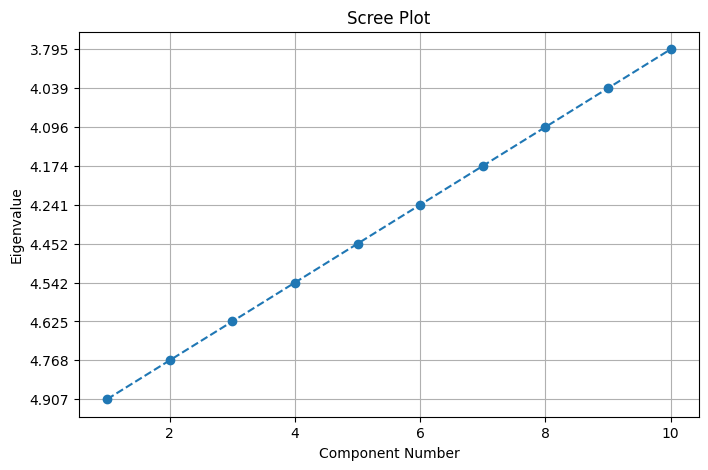

In [22]:
eigenvalues = famd.eigenvalues_summary["eigenvalue"]
plt.figure(figsize=(8,5))
plt.plot(range(1,11), eigenvalues, marker="o", linestyle="--")
plt.title("Scree Plot")
plt.xlabel("Component Number")
plt.ylabel("Eigenvalue")
plt.grid(True)
plt.show()

In [24]:
famd = prince.FAMD(
    n_components=16,    #max possible
    random_state=39
).fit(df)

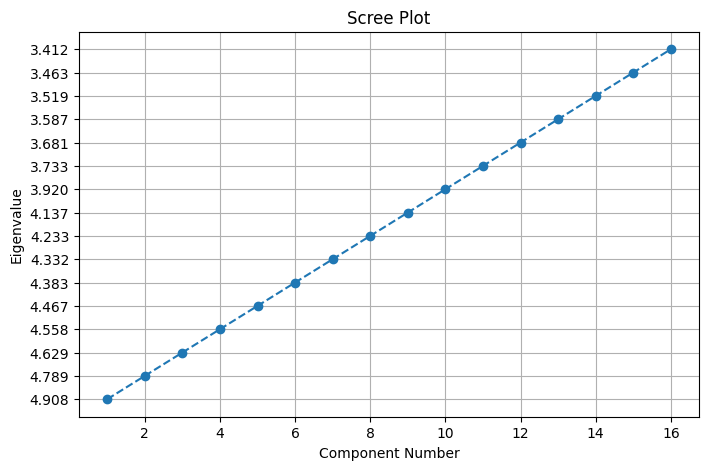

In [25]:
eigenvalues = famd.eigenvalues_summary["eigenvalue"]
plt.figure(figsize=(8,5))
plt.plot(range(1,17), eigenvalues, marker="o", linestyle="--")
plt.title("Scree Plot")
plt.xlabel("Component Number")
plt.ylabel("Eigenvalue")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#take the results of famd (the new coordinates for the rows) and converts them into np array
X_famd_all = famd.row_coordinates(df).values #rows are still in the shape of original df, but columns becomes Component0, Component1,...
dims_to_try = [2,3,4,5] #try the first 2 comp, then increase up to 5 comps, one by one
K_range = range(2, 7)   #for each dim setting, try to split the data into 2,3,4,5,6 clusters

#it slices the data to take only the first d columns
for d in dims_to_try:
    X_d = X_famd_all[:, :d] # : means 'keep all rows' & :d means 'keep columns (Components) from index 0 up to d (but not including)'
    best_sil = -1 # set the worst value frist and replace it with the value of 'if sil>best_sil:'
    best_k = None

    for k in K_range: 
        km = KMeans(n_clusters=k, n_init=20, random_state=39) #runs the clustering algorithm for every k in the range.
        labels = km.fit_predict(X_d)
        sil = silhouette_score(X_d, labels)
        if sil > best_sil:
            best_sil = sil
            best_k = k
    print(f"d={d}: best k={best_k}, best_silhouette={best_sil:.3f}")

d=2: best k=3, best_silhouette=0.360
d=3: best k=4, best_silhouette=0.251
d=4: best k=5, best_silhouette=0.224
d=5: best k=6, best_silhouette=0.186


In [27]:
col_coords = famd.column_coordinates_
print(col_coords.head(20))
#the main 'column' method meaning column_correlations (variables vs components)

component                      0         1         2         3         4   \
variable                                                                    
Daily_Screen_Time_hrs    0.001032  0.003127  0.000523  0.003184  0.008305   
Social_Media_Usage_hrs   0.001173  0.007062  0.000122  0.008486  0.003474   
Age                      0.464107  0.409222  0.348348  0.288436  0.483153   
Gaming_Activity          0.141919  0.009319  0.104826  0.007041  0.174110   
Gender                   0.084461  0.004335  0.105544  0.033045  0.061319   
Preferred_Device         0.257130  0.196644  0.189636  0.297004  0.197872   
Privacy_Awareness_Level  0.050565  0.314943  0.245865  0.040553  0.034882   
Streaming_Subscriptions  0.228129  0.271480  0.191233  0.395706  0.302971   
Tech_Savviness           0.180803  0.162365  0.139569  0.237425  0.021639   

component                      5         6         7         8         9   \
variable                                                                   

In [28]:
#get famd scores for each individual
row_coords = famd.row_coordinates(df)   #projection of original df into famd-reduced space; the result is pd 
row_coords.columns = [f'Dim{i+1}' for i in range(row_coords.shape[1])]  #overwrites the existing integer-based column names (0,1,2,..) with Dim1,Dim2,..
#.shape[0] represents 1st in tuple>> total no of rows; .shape[1] >> total no. of columns

In [ ]:
## WON'T use for the model as famd.column_coordinates_ is more suitable
#num_cols = ["Age", "Daily_Screen_Time_hrs", "Social_Media_Usage_hrs", "Streaming_Subscriptions"]
#corr_num = pd.DataFrame(index=num_cols, columns=X_famd.columns, dtype=float)

#for col in num_cols:
    #for dim in X_famd.columns:
        #corr_num.loc[col, dim] = np.corrcoef(df[col].astype(float), X_famd[dim])[0,1]
# [0,1] is the example representation of corr between x and y. Can also be written as [1,0] 

#print(corr_num)

                             Dim1      Dim2      Dim3      Dim4      Dim5  \
Age                      0.058886 -0.064573 -0.088363  0.077397 -0.021371   
Daily_Screen_Time_hrs   -0.037716 -0.055608  0.025977 -0.057396 -0.090677   
Social_Media_Usage_hrs   0.035456  0.081036 -0.011011  0.092814  0.063968   
Streaming_Subscriptions  0.167926 -0.062069  0.082987 -0.097836  0.106158   

                             Dim6      Dim7      Dim8      Dim9     Dim10  \
Age                      0.079905 -0.597499  0.007252  0.021237 -0.161065   
Daily_Screen_Time_hrs   -0.019778 -0.108972 -0.001113 -0.156259  0.090023   
Social_Media_Usage_hrs   0.091563  0.052495 -0.030775 -0.021030  0.142749   
Streaming_Subscriptions  0.422113  0.222560  0.334010 -0.054627  0.262774   

                            Dim11     Dim12     Dim13     Dim14     Dim15  \
Age                      0.269166 -0.186911 -0.041865  0.273895  0.345088   
Daily_Screen_Time_hrs    0.029402  0.017424 -0.021032  0.005105 -0.034235 

In [29]:
#for category profiling, looking at the average position of each category within the new FAMD space
cat_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level", "Gender", "Preferred_Device"]
for col in cat_cols:
    print(f"\n=== {col} ===")
    tmp = row_coords.copy()
    tmp[col] = df[col].values
    print(tmp.groupby(col, observed=False)[["Dim1", "Dim2"]].mean())

#the axis used for the mean is rows axis (the average across rows), and the result is grouped by dimensions
#dimensions provide the 'scale' to measure the rows; the 'mean' is the final summary


=== Gaming_Activity ===
                     Dim1      Dim2
Gaming_Activity                    
1               -1.158497 -0.293085
2                0.633586  0.159581
3                0.566833  0.144197

=== Tech_Savviness ===
                    Dim1      Dim2
Tech_Savviness                    
1               1.507100 -0.060261
2              -0.490552 -1.100753
3              -0.161588 -0.127800
4              -0.951576  1.367624

=== Privacy_Awareness_Level ===
                             Dim1      Dim2
Privacy_Awareness_Level                    
1                        0.021098 -1.032133
2                        0.615475  1.747368
3                       -0.596198 -0.687971

=== Gender ===
            Dim1      Dim2
Gender                    
Female  0.721979 -0.184233
Male    0.038345  0.154103
Other  -0.821498  0.061443

=== Preferred_Device ===
                      Dim1      Dim2
Preferred_Device                    
Desktop          -1.705316 -1.233751
Laptop           -0.

In [31]:
pip install adjustText

Note: you may need to restart the kernel to use updated packages.


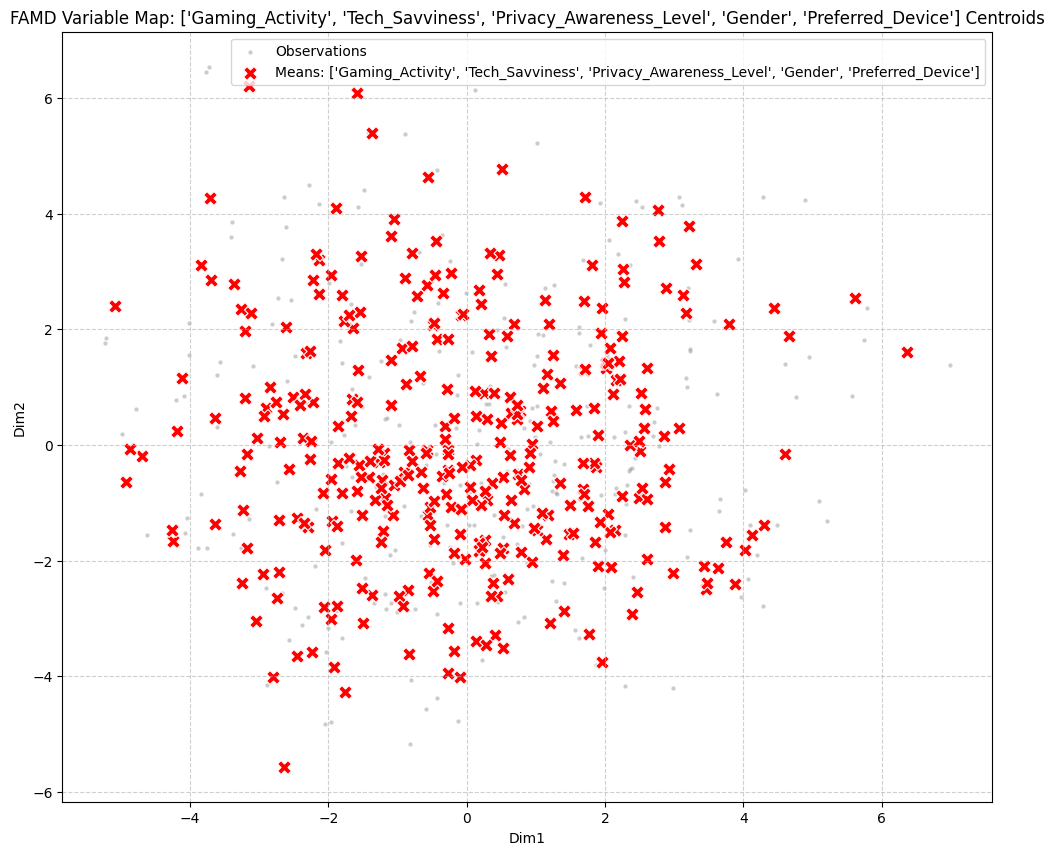

In [30]:
# 1. Set up the figure
plt.figure(figsize=(12, 10))

# 2. Plot background: All individual row coordinates
sns.scatterplot(
    data=row_coords, x='Dim1', y='Dim2', 
    alpha=0.4, color='gray', s=10, label='Observations'
)

# 3. Calculate and plot categorical means for a specific variable (e.g., 'Target_Column')
# Replace 'Target_Column' with your actual categorical column name
cat_col = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level", "Gender", "Preferred_Device"]
tmp = row_coords.copy()
tmp[cat_col] = df[cat_col].values
centers = tmp.groupby(cat_col)[["Dim1", "Dim2"]].mean()     #got the centroids by '.mean()'

# 4. Plot the centroids (means)
sns.scatterplot(
    data=centers, x='Dim1', y='Dim2',
    s=100, color='red', marker='X', label=f'Means: {cat_col}'
)

# 5. Add labels to the centroids
#for label, row in centers.iterrows():
    #plt.annotate(
        #label,
        #(row['Dim1'], row['Dim2']),
        #textcoords="offset points", 
        #xytext=(0,10), 
        #ha='center', 
        #fontweight='bold',
        #color='darkred'
    #)

plt.title(f'FAMD Variable Map: {cat_col} Centroids')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


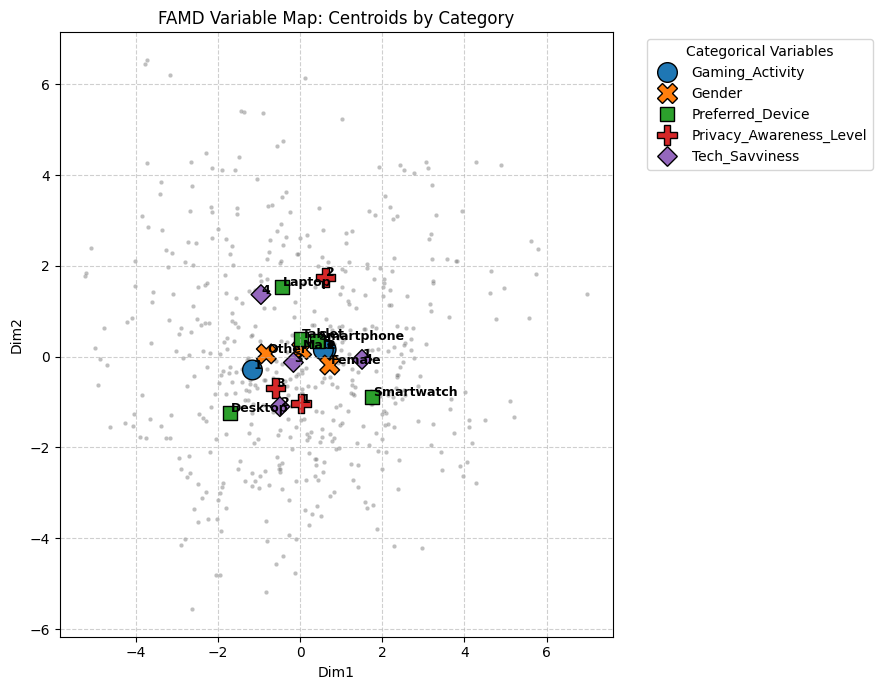

In [31]:
# 1. Set up the figure
plt.figure(figsize=(9, 7))

# 2. Plot background
sns.scatterplot(
    data=row_coords, x='Dim1', y='Dim2', 
    alpha=0.5, color='gray', s=10
)

# 3. Calculate centroids
cat_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level", "Gender", "Preferred_Device"]
tmp = row_coords.copy()
tmp[cat_cols] = df[cat_cols].values

# Group and reset index so Seaborn can access the category names for 'hue'
centers = tmp.melt(id_vars=['Dim1', 'Dim2'], value_vars=cat_cols, var_name='Category_Type', value_name='Level')
centers = centers.groupby(['Category_Type', 'Level'])[['Dim1', 'Dim2']].mean().reset_index()

# 4. Plot the centroids with color mapped to 'Category_Type'
sns.scatterplot(
    data=centers, x='Dim1', y='Dim2',
    hue='Category_Type',  # This changes the color per variable type
    style='Category_Type', # Optional: changes marker shape per variable type
    s=200, marker='X', edgecolor='black', linewidth=1
)

# 5. Add text labels for each specific level (e.g., "Male", "High")
for i in range(centers.shape[0]):
    plt.text(
        centers.Dim1[i]+0.02, centers.Dim2[i]+0.02, 
        centers.Level[i], fontsize=9, weight='bold'
    )

plt.title('FAMD Variable Map: Centroids by Category')
plt.legend(title='Categorical Variables', bbox_to_anchor=(1.05, 1), loc='upper left') # Legend outside
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


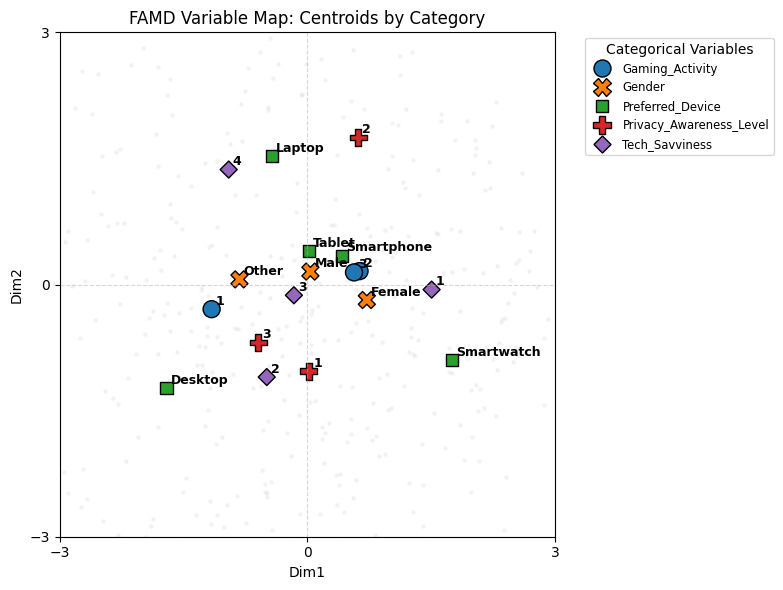

In [33]:
# 1. Set up a smaller figure size
plt.figure(figsize=(8, 6))

# 2. Plot background
sns.scatterplot(
    data=row_coords, x='Dim1', y='Dim2', 
    alpha=0.1, color='gray', s=10
)

# 3. Calculate centroids (Means)
cat_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level", "Gender", "Preferred_Device"]
tmp = row_coords.copy()
tmp[cat_cols] = df[cat_cols].values

# Melt and group to get centers for each category type
centers = tmp.melt(id_vars=['Dim1', 'Dim2'], value_vars=cat_cols, var_name='Category_Type', value_name='Level')
centers = centers.groupby(['Category_Type', 'Level'])[['Dim1', 'Dim2']].mean().reset_index()

# 4. Plot centroids with hue
sns.scatterplot(
    data=centers, x='Dim1', y='Dim2',
    hue='Category_Type',
    style='Category_Type', 
    s=150, marker='X', edgecolor='black', linewidth=1
)

# 5. Zoom and set scale to (-3, 0, 3)
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.xticks([-3, 0, 3])
plt.yticks([-3, 0, 3])

# 6. Add labels for each point
for i in range(len(centers)):
    plt.text(
        centers.Dim1[i] + 0.05, centers.Dim2[i] + 0.05, 
        centers.Level[i], fontsize=9, weight='semibold'
    )

plt.title('FAMD Variable Map: Centroids by Category')
plt.legend(title='Categorical Variables', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


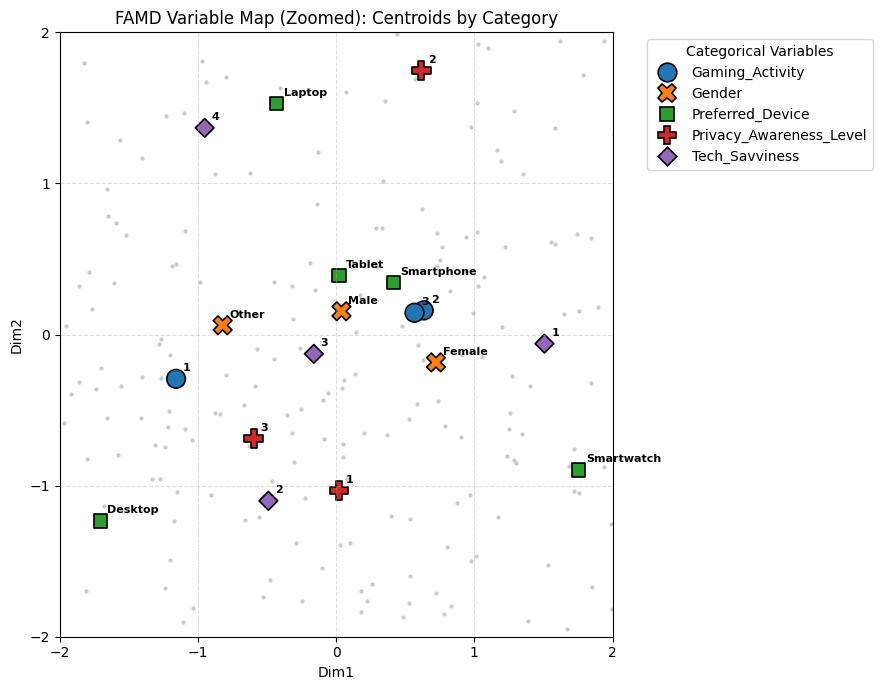

In [32]:
import numpy as np

# 1. Set up a more compact figure size
plt.figure(figsize=(9, 7))

# 2. Plot background (Observations)
sns.scatterplot(
    data=row_coords, x='Dim1', y='Dim2', 
    alpha=0.4, color='gray', s=10,
)

# 3. Calculate centroids
cat_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level", "Gender", "Preferred_Device"]
tmp = row_coords.copy()
tmp[cat_cols] = df[cat_cols].values

centers = tmp.melt(id_vars=['Dim1', 'Dim2'], value_vars=cat_cols, var_name='Category_Type', value_name='Level')
centers = centers.groupby(['Category_Type', 'Level'])[['Dim1', 'Dim2']].mean().reset_index()

# 4. Plot centroids with hue
sns.scatterplot(
    data=centers, x='Dim1', y='Dim2',
    hue='Category_Type', 
    style='Category_Type',
    s=180, marker='X', edgecolor='black', linewidth=1.2
)

# 5. Set the scale and show every integer from -3 to 3
ticks = np.arange(-2, 3) # Generates [-3, -2, -1, 0, 1, 2, 3]
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.xticks(ticks)
plt.yticks(ticks)

# 6. Add labels for each point
for i, row in centers.iterrows():
    plt.text(
        row['Dim1'] + 0.05, row['Dim2'] + 0.05, 
        row['Level'], fontsize=8, weight='bold'
    )

plt.title('FAMD Variable Map (Zoomed): Centroids by Category')
plt.legend(title='Categorical Variables', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [33]:
#1/ Data preparation (Get the first 2 famd components)
row_coords = famd.row_coordinates(df)   #reduce dimension acc to famd model
row_coords.columns = ["Dim1", "Dim2"] + list(row_coords.columns[2:])    #Dim renaming and selection & the rest of the components'names are preserved
X_2d = row_coords[["Dim1", "Dim2"]].values      #converts pd to np (std format for Scikit-Learn)

#2/ KMeans Configuration (k-means with k=3)
from sklearn.cluster import KMeans

kmeans_final = KMeans(n_clusters=3, n_init=20, random_state=39) #K-Means starts with random centers (centroids), so it can sometimes get 'stuck'. n_init prevents this.
cluster_labels = kmeans_final.fit_predict(X_2d)

df["cluster"] = cluster_labels  #the resulting labels (eg.0,1,2,..) are added back to your original df as a new column name 'cluster'
row_coords["cluster"] = cluster_labels  #.....added to row_coords frame

In [34]:
row_coords.head()

,Dim1,Dim2,2,3,4,5,6,7,8,9,10,11,12,13,14,15,cluster
0,-0.267301,-3.935113,-2.296078,1.941366,-2.000980,-2.916573,-3.620989,2.544891,2.709952,-0.323533,-1.487029,-0.644868,-2.333158,0.898940,-1.455975,-1.497008,0
1,-0.794555,1.707529,2.451917,1.256898,-2.364844,-1.354040,1.676147,-1.488063,1.885619,-0.876255,-0.801657,-0.418341,-0.440029,-4.220967,0.349892,-1.907219,2
2,-2.808845,2.094350,-2.247697,4.225070,-1.053447,-1.269547,2.183009,-1.823148,-3.162107,2.047318,0.475002,-0.473424,-0.545618,-2.101182,-0.731449,-1.186049,2
3,-1.653683,0.786639,-0.052834,-0.184629,2.065976,-1.127309,-2.693735,-2.558198,2.677549,-0.212275,1.526209,-3.014219,-3.168106,-1.087848,2.616686,0.811058,2
4,2.779949,-0.026051,4.293361,0.400198,-2.754366,0.370342,1.230652,-0.397107,0.030915,-2.532794,-0.691285,-1.815255,0.518943,1.869039,-0.383570,0.787830,1


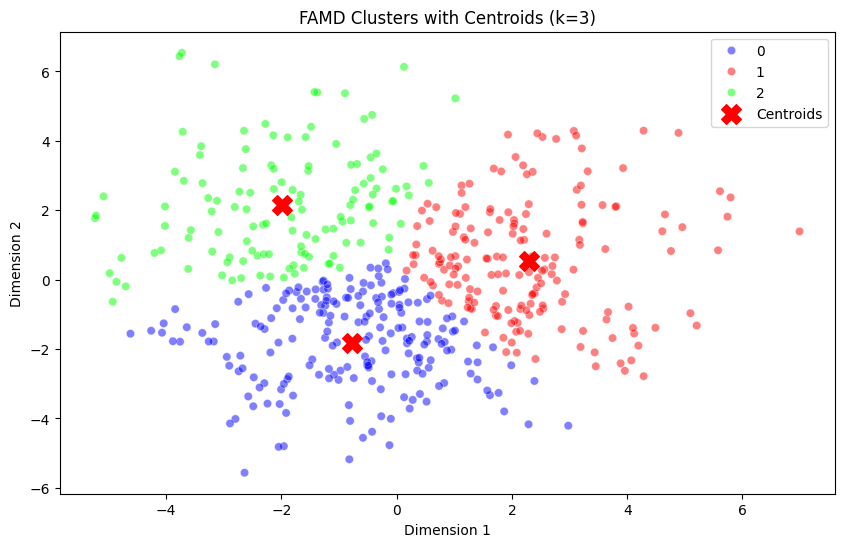

In [35]:
centroids = kmeans_final.cluster_centers_

plt.figure(figsize=(10, 6))

# Plot data points
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df['cluster'], palette='brg', alpha=0.5)

# FIX: Changed 'labels' to 'label'
plt.scatter(centroids[:, 0], centroids[:, 1], 
            c='red', 
            s=200, 
            marker='X', 
            label='Centroids') # Singular 'label' works here

plt.title('FAMD Clusters with Centroids (k=3)')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.show()


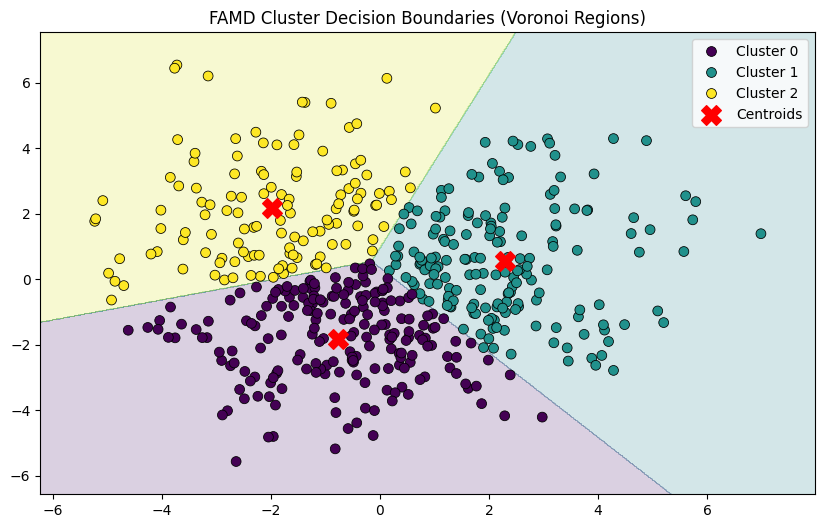

In [ ]:
#1/ Define the grid boundaries based on the famd dimensions
x_min, x_max = X_2d[:,0].min() -1, X_2d[:,0].max() +1
y_min, y_max = X_2d[:,1].min() -1, X_2d[:,1].max() +1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

#2/ Predict cluster for every point in the grid
Z = kmeans_final.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10,6))

#3/ Plot the decision boundaries (Voronoi region)
plt.contourf(xx, yy, Z, alpha=0.2, cmap="viridis")

#4/ Plot the actual data points
sns.scatterplot(x=X_2d[:,0], y=X_2d[:,1], hue=df["cluster"], palette="viridis", edgecolor="k", s=50)

#5/ Plot the centroids
centroids = kmeans_final.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:,1],
            c="red",
            s=200,
            marker="X",
            label="Centroids")

plt.title("FAMD Cluster Decision Boundaries (Voronoi Regions)")

# Grab the existing handles/labels from the plot
handles, labels = plt.gca().get_legend_handles_labels()

# Note: Seaborn often includes a 'title' handle for the hue column, 
# so map the names to the actual data handles.
custom_labels = ["Cluster 0", "Cluster 1", "Cluster 2", "Centroids"]

plt.legend(handles=handles[0:], labels=custom_labels)

plt.show()

In [41]:
#Numeric variables by cluster
cluster_means = df.groupby("cluster")[num_cols].mean()
print(cluster_means)

               Age  Daily_Screen_Time_hrs  Social_Media_Usage_hrs  \
cluster                                                             
0        23.631841               7.235821                3.400000   
1        23.954286               6.800000                3.715429   
2        23.814516               6.784677                3.683065   

         Streaming_Subscriptions  
cluster                           
0                       2.517413  
1                       2.662857  
2                       2.032258  


In [42]:
#Categorical/ordinal variables by cluster_labels
for col in cat_cols:
    print(f'\n=== {col} by cluster ===')
    print(pd.crosstab(df["cluster"], df[col], normalize="index"))
#proportions of each category within each cluster 


=== Gaming_Activity by cluster ===
Gaming_Activity         1         2         3
cluster                                      
0                0.432836  0.293532  0.273632
1                0.160000  0.457143  0.382857
2                0.451613  0.282258  0.266129

=== Tech_Savviness by cluster ===
Tech_Savviness         1         2         3         4
cluster                                               
0               0.203980  0.388060  0.243781  0.164179
1               0.445714  0.188571  0.211429  0.154286
2               0.104839  0.161290  0.233871  0.500000

=== Privacy_Awareness_Level by cluster ===
Privacy_Awareness_Level         1         2         3
cluster                                              
0                        0.432836  0.094527  0.472637
1                        0.297143  0.480000  0.222857
2                        0.177419  0.491935  0.330645

=== Gender by cluster ===
Gender     Female      Male     Other
cluster                              
0      

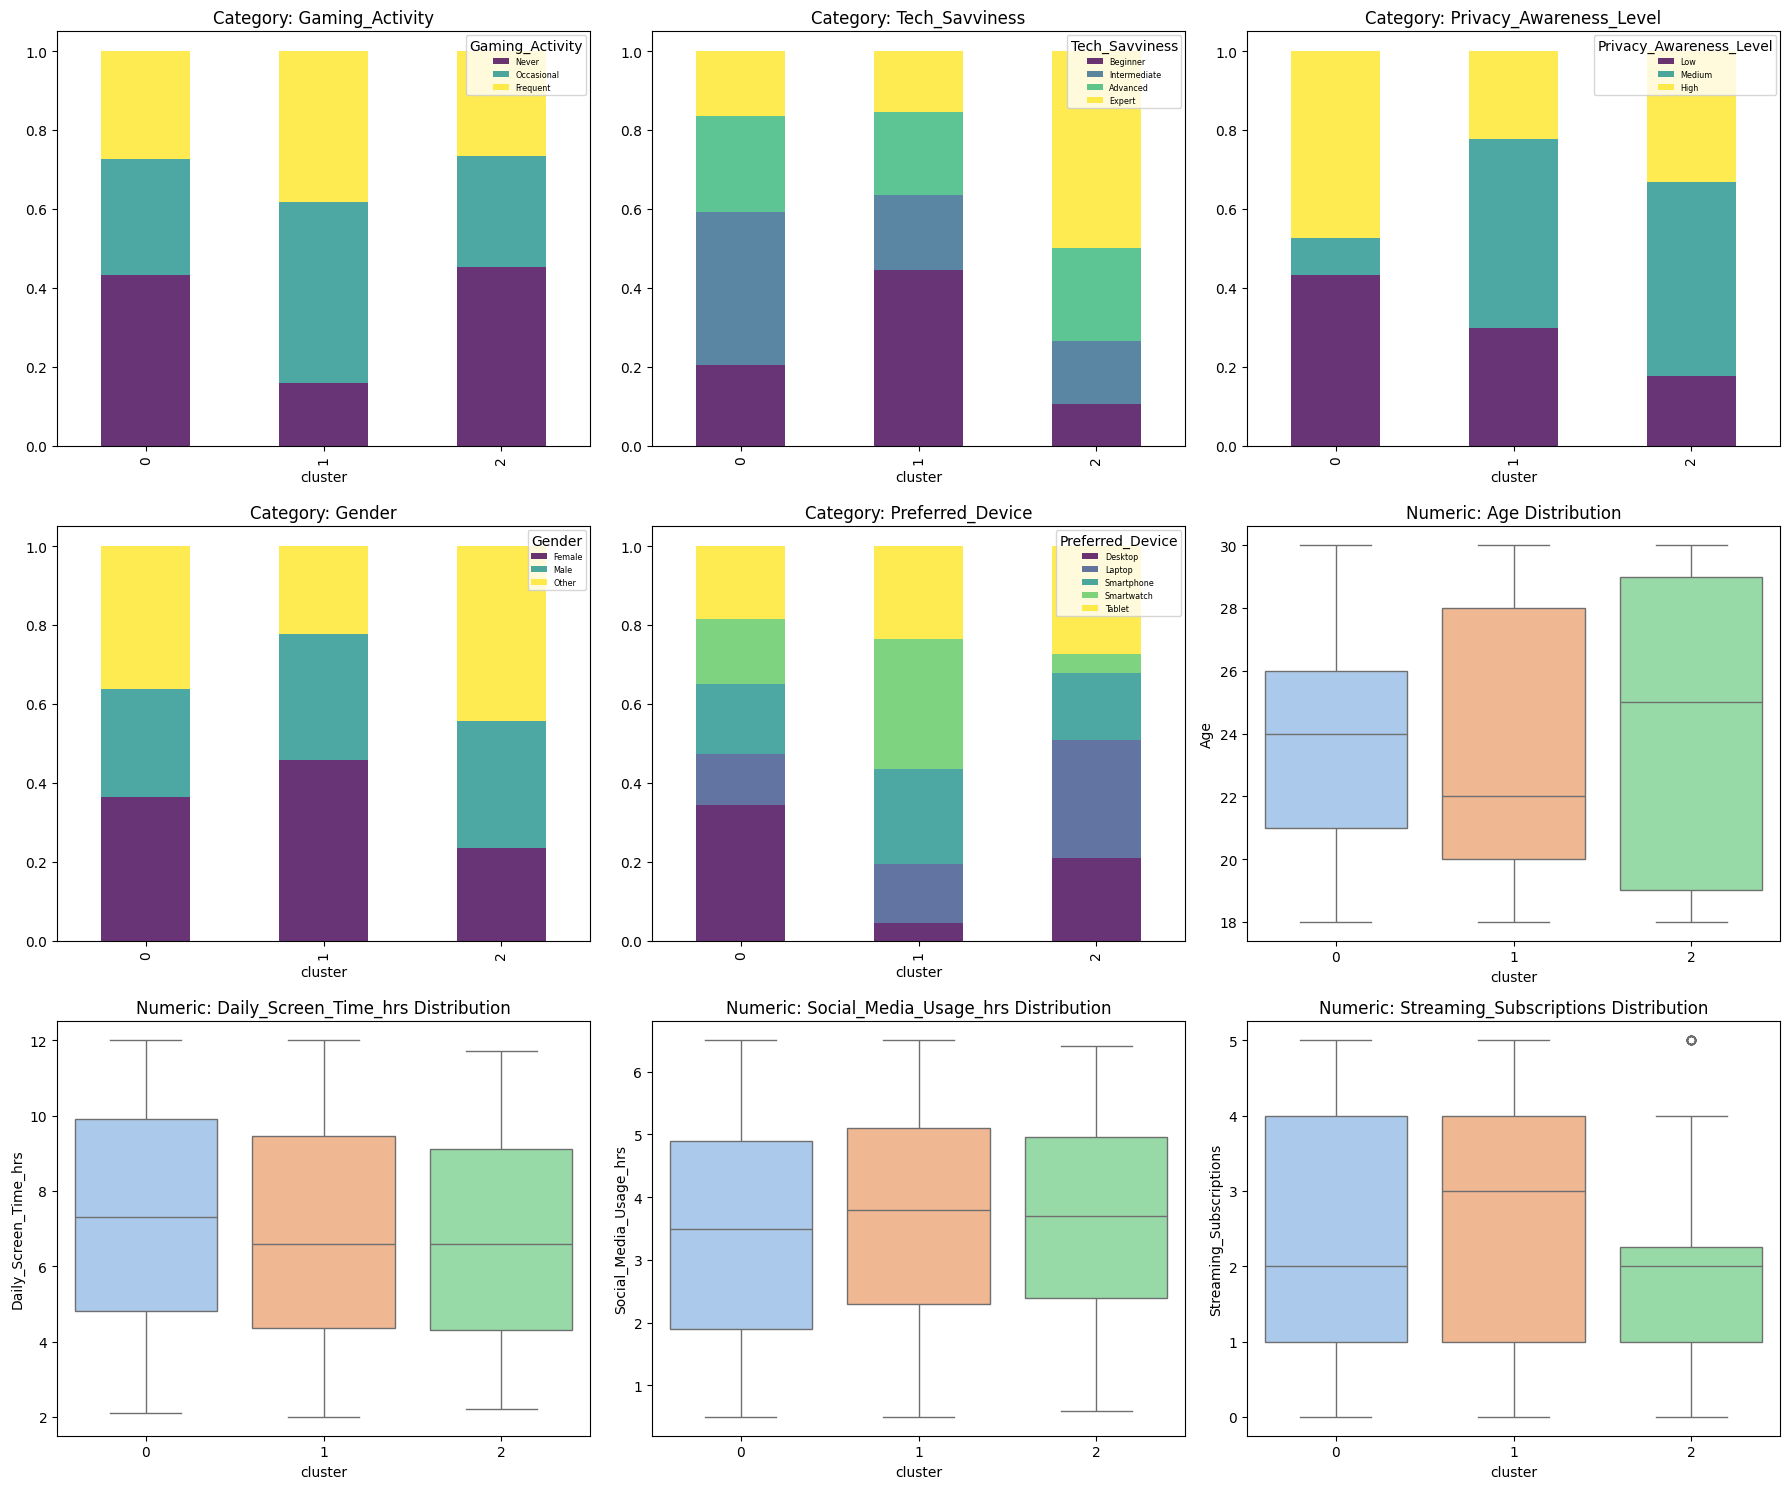

In [43]:
# 1. Define your label maps (Reversed so 1 -> 'Never', etc.)
label_maps = {
    "Gaming_Activity": {1: "Never", 2: "Occasional", 3: "Frequent"},
    "Tech_Savviness": {1: "Beginner", 2: "Intermediate", 3: "Advanced", 4: "Expert"},
    "Privacy_Awareness_Level": {1: "Low", 2: "Medium", 3: "High"}
}
# Define the lists
num_cols = ["Age", "Daily_Screen_Time_hrs", "Social_Media_Usage_hrs", "Streaming_Subscriptions"]
cat_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level", "Gender", "Preferred_Device"]
all_cols = cat_cols + num_cols

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15)) 
axes = axes.flatten()   #.flatten() is for (3,3) 2D to 1D list

for i, col in enumerate(all_cols):
    if col in cat_cols:
        #Use labels if they exit in the map, otherwise use the raw data
        temp_series = df[col].map(label_maps[col]) if col in label_maps else df[col]

        # Categorical: Use 100% Stacked Bar
        ct = pd.crosstab(df["cluster"], temp_series, normalize="index")
        
        # Ensure categories stay in the correct order (e.g., low to high)
        if col in label_maps:
            ordered_labels = [label_maps[col][k] for k in sorted(label_maps[col].keys())] #two sets of brackets [col][k]>>digging into a dict inside a dict (a nested dictionary)
            ct = ct.reindex(columns=ordered_labels) #reindex is crucial. without it, pandas might put "Frequent" before "Never" alphabetically 

        ct.plot(kind='bar', stacked=True, ax=axes[i], colormap='viridis', alpha=0.8)
        axes[i].set_title(f'Category: {col}')
        axes[i].legend(title=col, loc='upper right', fontsize='xx-small')
    else:
        # Numeric: Use Box Plot to show distribution differences
        sns.boxplot(x='cluster', y=col, hue='cluster', data=df, ax=axes[i], palette='pastel', legend=False)
        axes[i].set_title(f'Numeric: {col} Distribution')

plt.tight_layout()
plt.show()


In [44]:
print(row_coords.groupby("cluster")[["Dim1", "Dim2"]].mean())

             Dim1      Dim2
cluster                    
0       -0.766327 -1.812187
1        2.287872  0.547695
2       -1.986660  2.164540


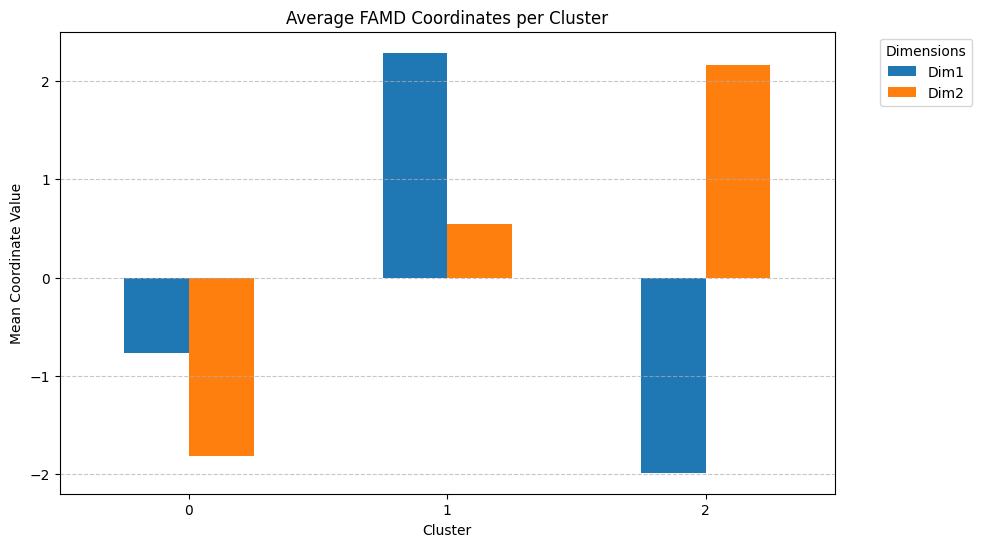

In [45]:
cluster_means = row_coords.groupby("cluster")[["Dim1", "Dim2"]].mean() 

cluster_means.plot(kind='bar', figsize=(10, 6))

# Move legend outside the plot to the right
plt.legend(title='Dimensions', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.title('Average FAMD Coordinates per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Mean Coordinate Value')
plt.xticks(rotation=0)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [46]:
df_dims = pd.concat([df.reset_index(drop=True),
                     row_coords[["Dim1", "Dim2"]].reset_index(drop=True)], axis=1)

In [47]:
num_cols = ["Age", "Daily_Screen_Time_hrs", "Social_Media_Usage_hrs", "Streaming_Subscriptions"]
corr_num = pd.DataFrame(index=num_cols, columns=["Dim1", "Dim2"], dtype=float)

for col in num_cols:
    for dim in ["Dim1", "Dim2"]:
        corr_num.loc[col, dim] = np.corrcoef(df_dims[col].astype(float), df_dims[dim])[0,1]

print(corr_num)

                             Dim1      Dim2
Age                      0.058886 -0.064573
Daily_Screen_Time_hrs   -0.037716 -0.055608
Social_Media_Usage_hrs   0.035456  0.081036
Streaming_Subscriptions  0.167926 -0.062069


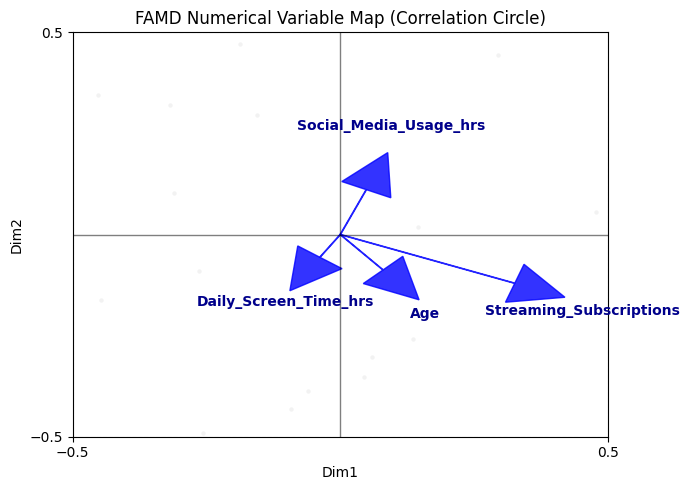

In [52]:
# 1. Set up the figure
plt.figure(figsize=(7, 5))

# 2. Plot background observations
sns.scatterplot(
    data=row_coords, x='Dim1', y='Dim2', 
    alpha=0.1, color='gray', s=10
)

# 1. Your manual calculation
corr_num = pd.DataFrame(index=num_cols, columns=["Dim1", "Dim2"], dtype=float)

for col in num_cols:
    for dim in ["Dim1", "Dim2"]:
        # Calculating Pearson correlation between the original column and the FAMD Dimension
        corr_num.loc[col, dim] = np.corrcoef(df_dims[col].astype(float), df_dims[dim])[0, 1]

# 2. Plotting the results using your new DataFrame
for col in num_cols:
    x_coord = corr_num.loc[col, "Dim1"]
    y_coord = corr_num.loc[col, "Dim2"]
    
    # Keeping your -3 to 3 scale visibility with a 2.5x multiplier
    plt.arrow(0, 0, x_coord * 2.5, y_coord * 2.5, color='blue', alpha=0.8, 
              head_width=0.1, head_length=0.1, length_includes_head=True)
    
    plt.text(x_coord * 2.7, y_coord * 3.2, col, color='darkblue', 
             weight='bold', fontsize=10, ha='center')


# 4. Set fixed integer scale from -3 to 3
ticks = np.arange(-0.5, 1)
plt.xlim(-0.5, 0.5)
plt.ylim(-0.5, 0.5)
plt.xticks(ticks)
plt.yticks(ticks)

# 5. Add origin lines (spines) for better quadrant visibility
plt.axhline(0, color='black', lw=1, alpha=0.5)
plt.axvline(0, color='black', lw=1, alpha=0.5)

plt.title('FAMD Numerical Variable Map (Correlation Circle)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


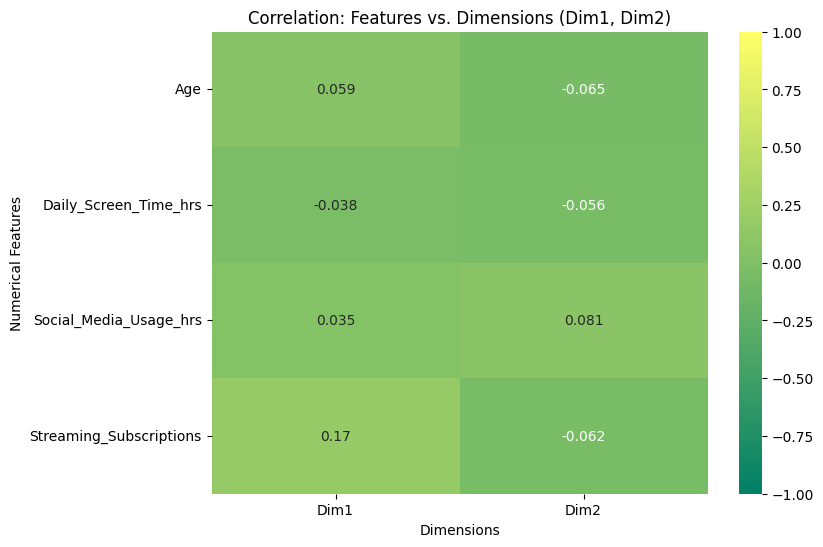

In [49]:
plt.figure(figsize=(8, 6))

# Create heatmap
sns.heatmap(corr_num, 
            annot=True,       # Show correlation values in cells
            cmap="summer",    # Red-Blue diverging color map (standard for correlations)
            center=0,         # Ensure 0 is the neutral color
            vmin=-1, vmax=1)  # Set fixed scale for consistency

plt.title("Correlation: Features vs. Dimensions (Dim1, Dim2)")
plt.ylabel("Numerical Features")
plt.xlabel("Dimensions")
plt.show()


In [50]:
cat_cols = ["Gaming_Activity", "Tech_Savviness", "Privacy_Awareness_Level", "Gender", "Preferred_Device"]
for col in cat_cols:
    print(f'\n=== {col} ===')
    print(df_dims.groupby(col, observed=False)[["Dim1", "Dim2"]].mean())
#observed=False: Includes every possible category defined in your data type, even if there are zero rows for it (result will show NaN).
#same as above


=== Gaming_Activity ===
                     Dim1      Dim2
Gaming_Activity                    
1               -1.158497 -0.293085
2                0.633586  0.159581
3                0.566833  0.144197

=== Tech_Savviness ===
                    Dim1      Dim2
Tech_Savviness                    
1               1.507100 -0.060261
2              -0.490552 -1.100753
3              -0.161588 -0.127800
4              -0.951576  1.367624

=== Privacy_Awareness_Level ===
                             Dim1      Dim2
Privacy_Awareness_Level                    
1                        0.021098 -1.032133
2                        0.615475  1.747368
3                       -0.596198 -0.687971

=== Gender ===
            Dim1      Dim2
Gender                    
Female  0.721979 -0.184233
Male    0.038345  0.154103
Other  -0.821498  0.061443

=== Preferred_Device ===
                      Dim1      Dim2
Preferred_Device                    
Desktop          -1.705316 -1.233751
Laptop           -0.

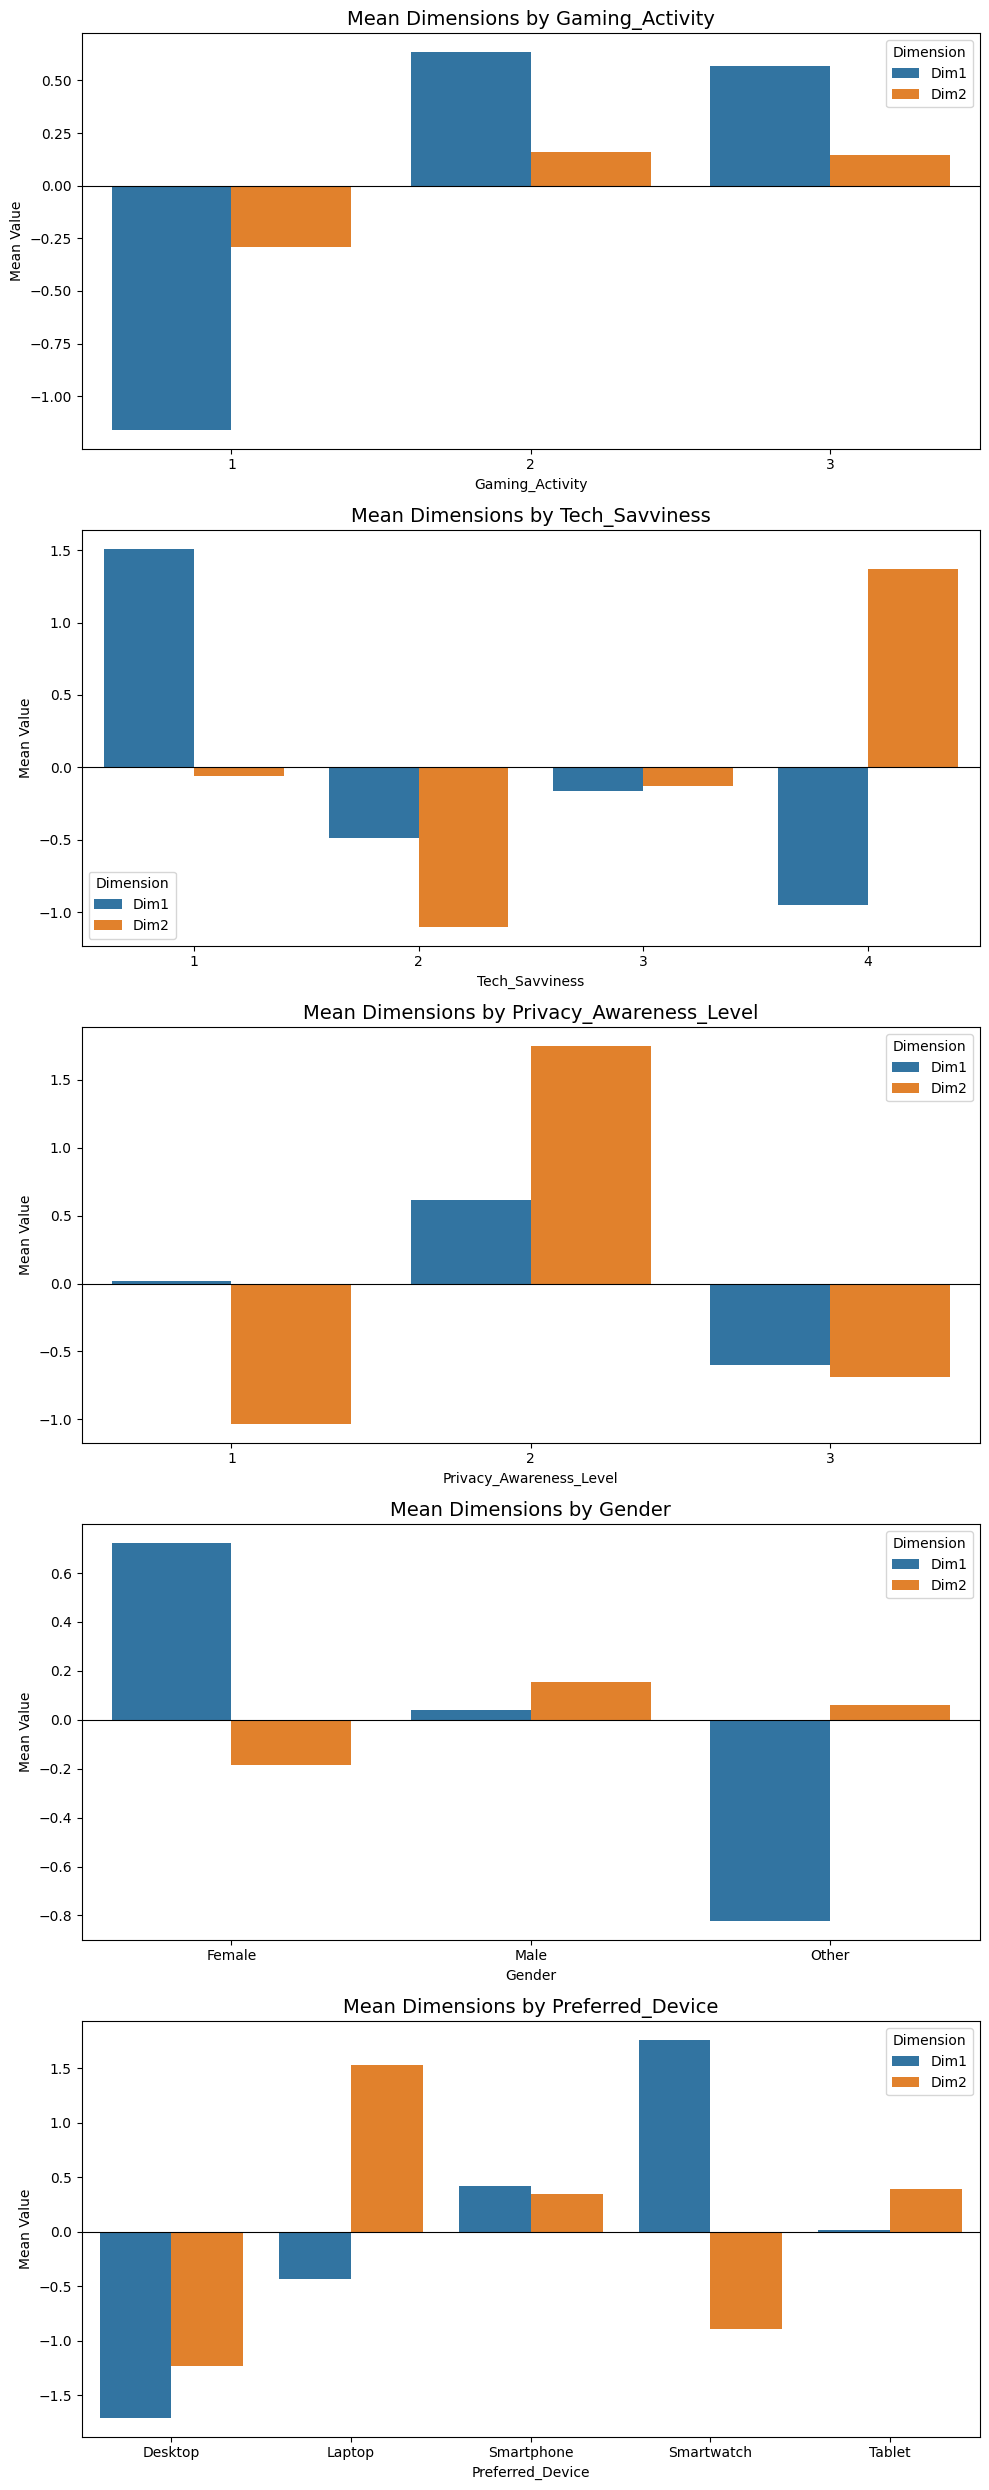

In [73]:
# Set up the figure for multiple subplots
fig, axes = plt.subplots(len(cat_cols), 1, figsize=(10, 5 * len(cat_cols)))

for i, col in enumerate(cat_cols):
    # Prepare the data by melting it into a long format for Seaborn
    df_plot = df_dims.groupby(col, observed=False)[["Dim1", "Dim2"]].mean().reset_index()
    df_melted = df_plot.melt(id_vars=col, var_name="Dimension", value_name="Mean Value")
    
    # Create the grouped bar chart
    sns.barplot(data=df_melted, x=col, y="Mean Value", hue="Dimension", ax=axes[i])
    
    # Clean up the visuals
    axes[i].set_title(f"Mean Dimensions by {col}", fontsize=14)
    axes[i].axhline(0, color='black', linewidth=0.8)  # Add a baseline for 0

plt.tight_layout()
plt.show()


In [51]:
#Numeric columns by cluster
#print(df_dims.groupby('cluster')[num_cols].mean())
#Cat columns by cluster
for col in cat_cols:
    print(f'\n=== {col} by cluster ===')
    print(pd.crosstab(df_dims['cluster'], df_dims[col], normalize='index'))


=== Gaming_Activity by cluster ===
Gaming_Activity         1         2         3
cluster                                      
0                0.432836  0.293532  0.273632
1                0.160000  0.457143  0.382857
2                0.451613  0.282258  0.266129

=== Tech_Savviness by cluster ===
Tech_Savviness         1         2         3         4
cluster                                               
0               0.203980  0.388060  0.243781  0.164179
1               0.445714  0.188571  0.211429  0.154286
2               0.104839  0.161290  0.233871  0.500000

=== Privacy_Awareness_Level by cluster ===
Privacy_Awareness_Level         1         2         3
cluster                                              
0                        0.432836  0.094527  0.472637
1                        0.297143  0.480000  0.222857
2                        0.177419  0.491935  0.330645

=== Gender by cluster ===
Gender     Female      Male     Other
cluster                              
0      

In [16]:
pip install -U ipykernel ipython altair

   ---------------------------------------- 0.0/625.7 kB ? eta -:--:--
   ---------------- ----------------------- 262.1/625.7 kB ? eta -:--:--
   ---------------------------------------- 625.7/625.7 kB 3.5 MB/s  0:00:00
   ---------------------------------------- 0.0/797.0 kB ? eta -:--:--
   ------------- -------------------------- 262.1/797.0 kB ? eta -:--:--
   ---------------------------------------  786.4/797.0 kB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 797.0/797.0 kB 1.6 MB/s  0:00:00

  Attempting uninstall: jupyter-client

    Found existing installation: jupyter_client 8.7.0

    Uninstalling jupyter_client-8.7.0:

      Successfully uninstalled jupyter_client-8.7.0

   ---------------------------------------- 0/4 [jupyter-client]
   ---------------------------------------- 0/4 [jupyter-client]
   ---------------------------------------- 0/4 [jupyter-client]
   ---------------------------------------- 0/4 [jupyter-client]
   --------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [18]:
pip install "altair<5.3"

   ---------------------------------------- 0.0/996.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/996.9 kB ? eta -:--:--
   --------------------- ------------------ 524.3/996.9 kB 2.7 MB/s eta 0:00:01
   ---------------------------------------- 996.9/996.9 kB 2.3 MB/s  0:00:00

   ---------------------------------------- 0/2 [toolz]
   ---------------------------------------- 0/2 [toolz]
   ---------------------------------------- 0/2 [toolz]
   ---------------------------------------- 0/2 [toolz]
  Attempting uninstall: altair
   ---------------------------------------- 0/2 [toolz]
    Found existing installation: altair 6.1.0
   ---------------------------------------- 0/2 [toolz]
    Uninstalling altair-6.1.0:
   ---------------------------------------- 0/2 [toolz]
   -------------------- ------------------- 1/2 [altair]
      Successfully uninstalled altair-6.1.0
   -------------------- ------------------- 1/2 [altair]
   -------------------- ------------------